SUPERMARKET QUEUE SIMULATION PRO
Duration: 300s | base rate: 0.08/s | rush hour: True
Total arrivals: 29 | mean basket: 11.5 items | express-eligible: 52%


,Configuration,Arrivals,Served,Lost (balk+renege),Lost %,Avg wait (s),Median (s),P95 wait (s),Max wait (s),Wait<=30s (%),Max queue,Avg util (%),Jockey moves
0,1 counter,29,12,12,41.4,50.3,41.0,110.2,124.0,38.5,9,95.3,0
1,2 counters,29,21,4,13.8,25.4,21.0,55.9,57.0,56.5,10,81.3,4
2,3 counters,29,28,0,0.0,7.1,1.0,23.6,38.0,96.6,4,66.7,4
3,"3 counters, shared queue",29,28,0,0.0,7.7,3.0,25.0,27.0,100.0,4,66.7,0
4,3 counters (1 express),29,28,0,0.0,9.3,3.0,37.8,45.0,93.1,5,66.0,4


Notes: customers still in service at the end are not counted as served;
'Lost' = customers who balked (refused to join) + reneged (left while waiting).


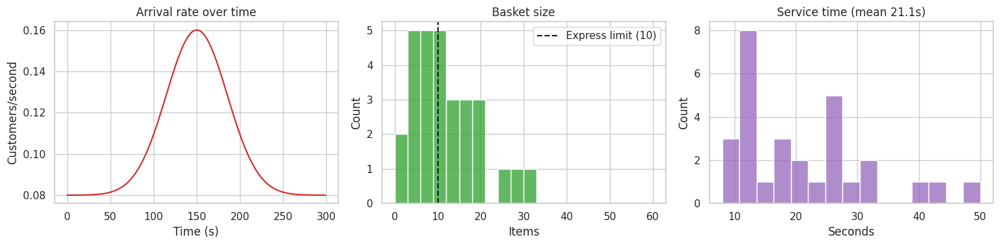

First customers' journey (3 counters (1 express)):


,customer,arrival,items,service_time,service_start,service_end,wait,counter,express_eligible
0,0,5,6,13,5,18,0,1,True
1,1,10,18,30,10,40,0,2,False
2,2,20,4,11,20,31,0,1,True
3,3,28,16,27,28,55,0,3,False
4,4,95,8,16,95,111,0,1,True
5,5,98,20,33,98,131,0,2,False
6,6,103,15,26,103,129,0,3,False
7,8,128,15,26,129,155,1,3,False
8,7,124,32,50,131,181,7,2,False
9,9,133,3,9,133,142,0,1,True


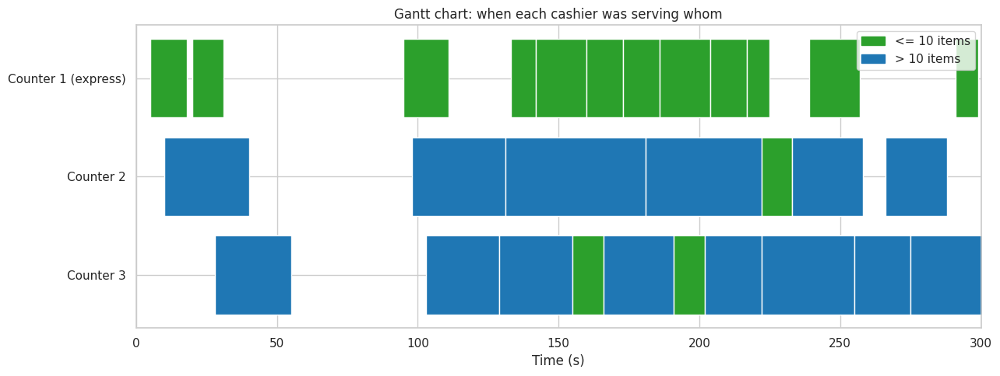

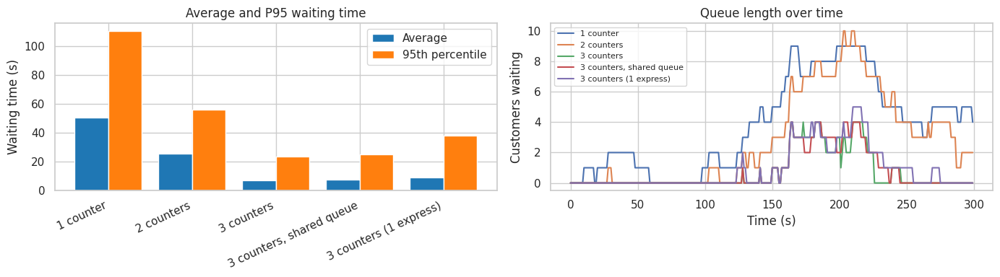

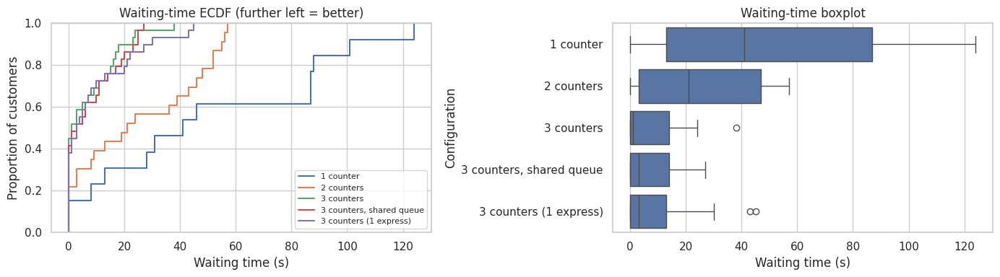

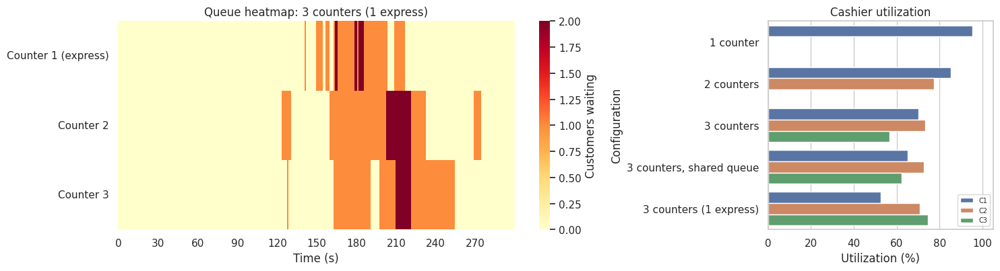

Mean +/- 95% confidence interval over 30 independent runs:


,Configuration,Avg wait (s),P95 wait (s),Lost (%),Cost (BDT/h)
0,1 counter,44.6 +/- 4.0,84.9 +/- 6.9,43.4 +/- 3.6,11251.3 +/- 1515.7
1,2 counters,24.2 +/- 4.0,56.7 +/- 6.4,10.9 +/- 3.4,3645.8 +/- 1046.5
2,3 counters,8.8 +/- 2.9,28.3 +/- 6.6,1.7 +/- 1.2,1318.8 +/- 392.1
3,"3 counters, shared queue",9.5 +/- 3.1,26.8 +/- 6.1,1.2 +/- 1.0,1204.2 +/- 347.2
4,3 counters (1 express),8.8 +/- 2.2,30.7 +/- 5.7,1.9 +/- 1.3,1392.1 +/- 405.2



HYPOTHESIS TESTS (alpha = 0.05)
1 counter (A) vs 2 counters (B), Welch two-sample t-test:
  mean A = 44.6s, mean B = 24.2s, t = 7.33, p = 8.26e-10, Cohen's d = 1.89 -> evidence of a difference in mean waiting time
3 separate queues (A) vs 3 counters with ONE shared queue (B), paired t-test (same customers in both):
  mean A = 8.8s, mean B = 9.5s, t = -2.26, p = 0.0316, Cohen's d = -0.09 -> evidence of a difference in mean waiting time (but the effect size is negligible)
3 separate queues (A) vs 3 counters with 1 express lane (B), paired t-test:
  mean A = 8.8s, mean B = 8.8s, t = -0.02, p = 0.981, Cohen's d = -0.00 -> no significant evidence of a difference


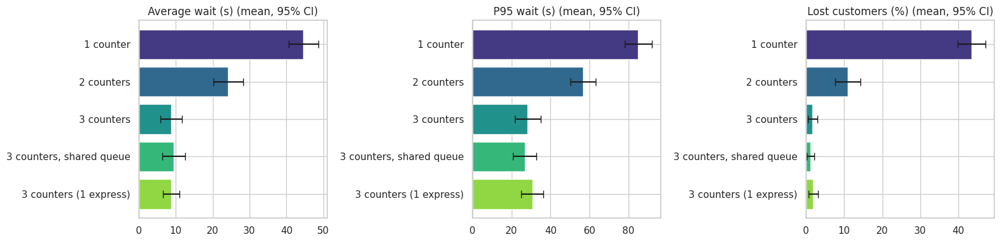

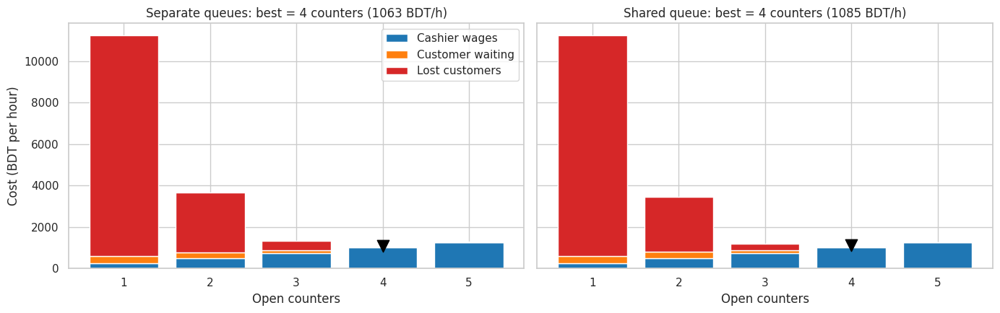

Cost parameters are assumptions: change COUNTER_COST_PER_HOUR, WAIT_COST_PER_HOUR, LOST_CUSTOMER_COST.


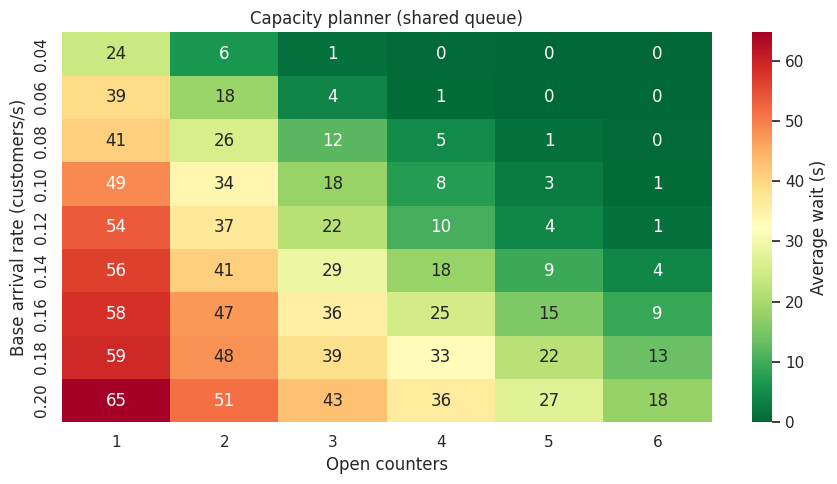

Smallest number of counters with >= 80% of customers waiting <= 30s and <= 5% lost:


,Arrival rate (/s),Customers per hour,Recommended counters
0,0.04,144,2
1,0.06,216,3
2,0.08,288,3
3,0.10,360,4
4,0.12,432,4
5,0.14,504,5
6,0.16,576,6
7,0.18,648,6
8,0.20,720,>6


Validation: 2 counters, one shared queue, no balking/reneging, uniform service 15-25s, 5 runs of 30000s per rate


,Arrival rate (/s),Utilization,Simulation (s),Std error (s),Theory (s),Difference (s)
0,0.05,0.5,3.37,0.11,3.42,-0.05
1,0.06,0.6,5.90,0.25,5.77,0.13
2,0.07,0.7,9.56,0.45,9.85,-0.29
3,0.08,0.8,17.64,0.96,18.22,-0.58
4,0.09,0.9,40.82,5.45,43.70,-2.88


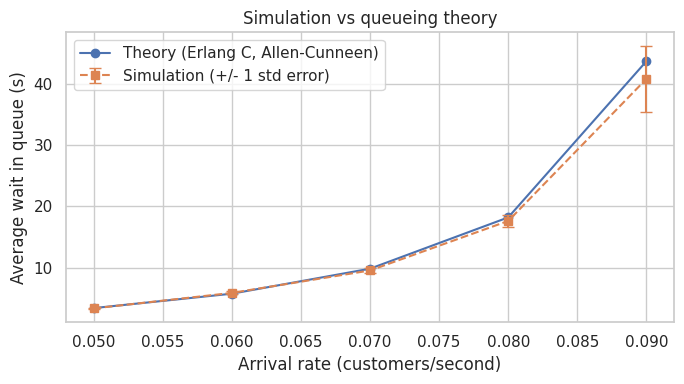

The Allen-Cunneen formula is itself an approximation (M/G/c), and waits are very noisy
at high utilization, so judge the match using the error bars, not the exact gap.


interactive(children=(FloatSlider(value=0.08, continuous_update=False, description='Arrival rate', max=0.25, m…

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================================
# Supermarket Queue Simulation PRO
# Google Colab-ready (paste into one cell, or split at the "# %%" lines)
#
# Extra features compared with the basic version:
#   1. Rush hour (time-varying Poisson arrivals)
#   2. Basket size (items) based service time
#   3. Three checkout layouts: separate queues, ONE shared queue, express lane
#   4. Customer behaviour: balking, reneging (abandoning), jockeying
#   5. Richer metrics: P90/P95, service level, lost customers, utilization
#   6. Customer journey log + Gantt chart of every cashier
#   7. Cost model + optimal number of counters
#   8. Capacity planner (recommended counters for each arrival rate)
#   9. Statistics: 95% confidence intervals, Welch / paired t-tests, effect size
#  10. Validation against queueing theory (Erlang C / Allen-Cunneen)
#  11. Interactive dashboard with sliders
# ==========================================================

# %% 0. IMPORTS
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import HTML, display

sns.set_theme(style="whitegrid")
plt.rcParams["animation.embed_limit"] = 100  # MB, allows a bigger animation in Colab

# %% 1. SETTINGS  (example values, NOT real supermarket measurements)
SIMULATION_TIME = 300          # seconds
BASE_ARRIVAL_RATE = 0.08       # customers per second (outside rush hour)
RANDOM_SEED = 42
N_RUNS = 30                    # repeated runs for statistics

# --- Rush hour: the arrival rate rises to BASE * (1 + RUSH_BOOST) at the peak
RUSH_HOUR = True
RUSH_PEAK_TIME = 150
RUSH_WIDTH = 50
RUSH_BOOST = 1.0

# --- Basket size and service time
USE_ITEM_BASED_SERVICE = True  # False = plain uniform(15, 25) seconds
BASKET_LOG_MEAN = 2.2          # lognormal basket size (median about 9 items)
BASKET_LOG_SIGMA = 0.7
BASE_SERVICE_SECONDS = 5       # payment / greeting time
SECONDS_PER_ITEM = 1.4         # scanning + packing time per item

# --- Express lane
EXPRESS_LIMIT = 10             # max items allowed in the express lane

# --- Customer behaviour
BALKING = True                 # customer refuses to join a very long line
BALK_THRESHOLD = 6             # people in line (per counter) that triggers balking
BALK_PROB = 0.7
RENEGING = True                # customer leaves after waiting too long
MIN_PATIENCE = 30              # seconds
MEAN_EXTRA_PATIENCE = 90       # exponential, seconds
JOCKEYING = True               # customer switches to a clearly shorter line

# --- Targets and cost model (assumptions, change them freely)
SERVICE_LEVEL_SECONDS = 30     # "good service" = waits at most this long
TARGET_SERVICE_LEVEL = 80      # % of served customers within the limit
TARGET_MAX_LOST_PCT = 5        # % of customers lost (balk + renege)
COUNTER_COST_PER_HOUR = 250    # BDT per open counter per hour
WAIT_COST_PER_HOUR = 100       # BDT, value of one customer-hour of waiting
LOST_CUSTOMER_COST = 60        # BDT profit lost when a customer leaves


# %% 2. CONFIGURATION OF A CHECKOUT SYSTEM
@dataclass(frozen=True)
class Config:
    counters: int = 2
    kind: str = "separate"          # "separate" | "single" | "express"
    express_counters: int = 1       # used only when kind == "express"
    express_limit: int = EXPRESS_LIMIT
    jockeying: bool = JOCKEYING
    balking: bool = BALKING
    reneging: bool = RENEGING


def cfg_label(cfg):
    if cfg.kind == "single":
        return f"{cfg.counters} counters, shared queue"
    if cfg.kind == "express":
        return f"{cfg.counters} counters ({cfg.express_counters} express)"
    return f"{cfg.counters} counter" + ("s" if cfg.counters > 1 else "")


# %% 3. CUSTOMER GENERATION
def arrival_rate_curve(base_rate, sim_time, rush):
    t = np.arange(sim_time)
    if not rush:
        return np.full(sim_time, float(base_rate))
    return base_rate * (1 + RUSH_BOOST * np.exp(-((t - RUSH_PEAK_TIME) / RUSH_WIDTH) ** 2))


def generate_customers(seed, base_rate=BASE_ARRIVAL_RATE, sim_time=SIMULATION_TIME,
                       rush=RUSH_HOUR, item_based=USE_ITEM_BASED_SERVICE):
    """Return (customers_by_time, total). Everything random is drawn here, so every
    checkout configuration sees exactly the same customers (fair comparison)."""
    rng = np.random.default_rng(seed)
    rate = arrival_rate_curve(base_rate, sim_time, rush)
    arrivals = rng.poisson(rate)
    total = int(arrivals.sum())

    items = np.clip(np.round(rng.lognormal(BASKET_LOG_MEAN, BASKET_LOG_SIGMA, total)),
                    1, 60).astype(int)
    if item_based:
        service = np.maximum(1, np.round(BASE_SERVICE_SECONDS + SECONDS_PER_ITEM * items)).astype(int)
    else:
        service = rng.integers(15, 26, size=total)
    patience = MIN_PATIENCE + rng.exponential(MEAN_EXTRA_PATIENCE, total)
    balk_u = rng.random(total)

    by_time = [[] for _ in range(sim_time)]
    cid = 0
    for t in range(sim_time):
        for _ in range(int(arrivals[t])):
            by_time[t].append({"id": cid, "arrival": t, "items": int(items[cid]),
                               "service": int(service[cid]),
                               "patience": float(patience[cid]),
                               "balk_u": float(balk_u[cid])})
            cid += 1
    return by_time, total


def items_lookup(customers_by_time):
    return np.array([c["items"] for batch in customers_by_time for c in batch])


# %% 4. SIMULATION ENGINE
def run_simulation(customers_by_time, cfg, sim_time=SIMULATION_TIME, warmup=0, record=True):
    n = cfg.counters
    single = cfg.kind == "single"
    express = cfg.kind == "express"
    n_exp = cfg.express_counters if express else 0
    if express and not (0 < n_exp < n):
        raise ValueError("Express layout needs at least one express and one regular counter.")

    nq = 1 if single else n
    queues = [[] for _ in range(nq)]
    active = [None] * n
    remaining = [0] * n
    busy_sec = [0] * n

    all_lanes = list(range(n))
    regular_lanes = list(range(n_exp, n))

    wait_records, abandon_records, balked_arrivals = [], [], []
    served = jockey_moves = 0
    queue_sum = queue_max = 0
    lost_so_far = 0
    total_queue_hist = []
    queue_history, queue_snapshots, active_snapshots = [], [], []
    served_hist, lost_hist, log = [], [], []

    def lanes_for(c):
        if express and c["items"] > cfg.express_limit:
            return regular_lanes
        return all_lanes

    for t in range(sim_time):

        # A. progress services
        for i in range(n):
            if active[i] is not None:
                remaining[i] -= 1
                if remaining[i] <= 0:
                    active[i] = None
                    served += 1

        # B. reneging: customers who waited longer than their patience leave
        if cfg.reneging:
            for q in queues:
                if q:
                    stay = []
                    for c in q:
                        if t - c["arrival"] > c["patience"]:
                            abandon_records.append((c["arrival"], t - c["arrival"]))
                            lost_so_far += 1
                        else:
                            stay.append(c)
                    q[:] = stay

        # C. arrivals choose a line (or balk)
        for c in customers_by_time[t]:
            if single:
                busy_now = sum(1 for a in active if a is not None)
                perceived = (len(queues[0]) + busy_now) / n
                pick = 0
            else:
                lens = [len(queues[i]) + (active[i] is not None) for i in range(n)]
                pick = min(lanes_for(c), key=lambda i: lens[i])
                perceived = lens[pick]
            if cfg.balking and perceived >= BALK_THRESHOLD and c["balk_u"] < BALK_PROB:
                balked_arrivals.append(c["arrival"])
                lost_so_far += 1
                continue
            queues[pick].append(c)

        # D. jockeying: last person in a line moves if another line is 2+ shorter
        if cfg.jockeying and not single:
            lens = [len(queues[i]) + (active[i] is not None) for i in range(n)]
            for i in range(n):
                if queues[i]:
                    c = queues[i][-1]
                    options = [j for j in lanes_for(c) if j != i]
                    if not options:
                        continue
                    j = min(options, key=lambda k: lens[k])
                    if lens[j] <= lens[i] - 2:
                        queues[i].pop()
                        queues[j].append(c)
                        lens[i] -= 1
                        lens[j] += 1
                        jockey_moves += 1

        # E. idle counters start serving
        for i in range(n):
            if active[i] is None:
                q = queues[0] if single else queues[i]
                if q:
                    c = q.pop(0)
                    active[i] = c
                    remaining[i] = c["service"]
                    wait = t - c["arrival"]                       # W = S - A
                    wait_records.append((c["arrival"], wait))
                    if record:
                        log.append({"customer": c["id"], "arrival": c["arrival"],
                                    "items": c["items"], "service_time": c["service"],
                                    "service_start": t, "service_end": t + c["service"],
                                    "wait": wait, "counter": i + 1,
                                    "express_eligible": c["items"] <= cfg.express_limit})

        # F. record data
        qtot = sum(len(q) for q in queues)
        total_queue_hist.append(qtot)
        if t >= warmup:
            for i in range(n):
                if active[i] is not None:
                    busy_sec[i] += 1
            queue_sum += qtot
            queue_max = max(queue_max, qtot)
        if record:
            queue_history.append([len(q) for q in queues])
            queue_snapshots.append([[c["id"] for c in q] for q in queues])
            active_snapshots.append([a["id"] if a is not None else None for a in active])
            served_hist.append(served)
            lost_hist.append(lost_so_far)

    # ---- final statistics
    duration = max(1, sim_time - warmup)
    waits = np.array([w for a, w in wait_records if a >= warmup], dtype=float)
    aband = np.array([w for a, w in abandon_records if a >= warmup], dtype=float)
    n_balk = sum(1 for a in balked_arrivals if a >= warmup)
    n_renege = len(aband)
    n_arr = sum(len(b) for b in customers_by_time[warmup:sim_time])
    leftover = sum(sim_time - c["arrival"] for q in queues for c in q if c["arrival"] >= warmup)

    def pct(x, q):
        return float(np.percentile(x, q)) if len(x) else 0.0

    res = {
        "config": cfg, "duration": duration, "sim_time": sim_time,
        "arrivals": n_arr, "served": served,
        "balked": n_balk, "reneged": n_renege, "lost": n_balk + n_renege,
        "lost_pct": 100 * (n_balk + n_renege) / n_arr if n_arr else 0.0,
        "still_waiting": sum(len(q) for q in queues),
        "still_in_service": sum(1 for a in active if a is not None),
        "waits": waits,
        "avg_wait": float(waits.mean()) if len(waits) else 0.0,
        "median_wait": pct(waits, 50), "p90_wait": pct(waits, 90), "p95_wait": pct(waits, 95),
        "max_wait": float(waits.max()) if len(waits) else 0.0,
        "std_wait": float(waits.std()) if len(waits) else 0.0,
        "wait_ok_pct": 100 * float((waits <= SERVICE_LEVEL_SECONDS).mean()) if len(waits) else 100.0,
        "avg_queue": queue_sum / duration, "max_queue": queue_max,
        "utilization": [b / duration for b in busy_sec],
        "throughput": served / sim_time,
        "total_wait_s": float(waits.sum() + aband.sum() + leftover),
        "jockey_moves": jockey_moves,
        "total_queue_hist": np.array(total_queue_hist),
    }
    if record:
        res.update({
            "queue_history": np.array(queue_history),
            "queue_snapshots": queue_snapshots,
            "active_snapshots": active_snapshots,
            "served_history": served_hist,
            "lost_history": lost_hist,
            "log": pd.DataFrame(log),
        })
    return res


def cost_per_hour(res):
    """Hourly cost in BDT: cashiers + customer waiting + lost customers."""
    hours = res["duration"] / 3600
    staff = res["config"].counters * COUNTER_COST_PER_HOUR
    waiting = (res["total_wait_s"] / 3600) / hours * WAIT_COST_PER_HOUR
    lost = res["lost"] / hours * LOST_CUSTOMER_COST
    return staff, waiting, lost


def summary_row(name, res):
    return {
        "Configuration": name,
        "Arrivals": res["arrivals"], "Served": res["served"],
        "Lost (balk+renege)": res["lost"], "Lost %": round(res["lost_pct"], 1),
        "Avg wait (s)": round(res["avg_wait"], 1), "Median (s)": round(res["median_wait"], 1),
        "P95 wait (s)": round(res["p95_wait"], 1), "Max wait (s)": round(res["max_wait"], 1),
        f"Wait<={SERVICE_LEVEL_SECONDS}s (%)": round(res["wait_ok_pct"], 1),
        "Max queue": res["max_queue"],
        "Avg util (%)": round(100 * float(np.mean(res["utilization"])), 1),
        "Jockey moves": res["jockey_moves"],
    }


# %% 5. MAIN EXPERIMENT: same customers for every configuration
customers_by_time, total_arrivals = generate_customers(RANDOM_SEED)
ITEMS = items_lookup(customers_by_time)

configs = {cfg_label(c): c for c in [
    Config(1), Config(2), Config(3),
    Config(3, "single"), Config(3, "express"),
]}
results = {name: run_simulation(customers_by_time, cfg) for name, cfg in configs.items()}

print("SUPERMARKET QUEUE SIMULATION PRO")
print("=" * 56)
print(f"Duration: {SIMULATION_TIME}s | base rate: {BASE_ARRIVAL_RATE}/s | rush hour: {RUSH_HOUR}")
print(f"Total arrivals: {total_arrivals} | mean basket: {ITEMS.mean():.1f} items | "
      f"express-eligible: {100 * (ITEMS <= EXPRESS_LIMIT).mean():.0f}%")

summary_df = pd.DataFrame([summary_row(n, r) for n, r in results.items()])
display(summary_df)
summary_df.to_csv("simulation_summary.csv", index=False)
print("Notes: customers still in service at the end are not counted as served;")
print("'Lost' = customers who balked (refused to join) + reneged (left while waiting).")


# %% 6. INPUT ANALYSIS (what do the random inputs look like?)
expected_rate = arrival_rate_curve(BASE_ARRIVAL_RATE, SIMULATION_TIME, RUSH_HOUR)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(expected_rate, color="tab:red")
axes[0].set_title("Arrival rate over time")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Customers/second")

sns.histplot(ITEMS, bins=range(0, 62, 3), ax=axes[1], color="tab:green")
axes[1].axvline(EXPRESS_LIMIT, color="k", linestyle="--", label=f"Express limit ({EXPRESS_LIMIT})")
axes[1].set_title("Basket size")
axes[1].set_xlabel("Items")
axes[1].legend()

svc = np.array([c["service"] for b in customers_by_time for c in b])
sns.histplot(svc, bins=15, ax=axes[2], color="tab:purple")
axes[2].set_title(f"Service time (mean {svc.mean():.1f}s)")
axes[2].set_xlabel("Seconds")
plt.tight_layout()
plt.show()


# %% 7. CUSTOMER JOURNEY LOG + GANTT CHART
DEMO_NAME = "3 counters (1 express)"   # change to any key of `configs`
demo_cfg, demo = configs[DEMO_NAME], results[DEMO_NAME]

log_df = demo["log"]
print(f"First customers' journey ({DEMO_NAME}):")
display(log_df.head(10))
log_df.to_csv("customer_journey_log.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 2 + demo_cfg.counters))
for _, row in log_df.iterrows():
    color = "tab:green" if row["express_eligible"] else "tab:blue"
    ax.broken_barh([(row["service_start"], row["service_time"])],
                   (row["counter"] - 0.4, 0.8), facecolors=color, edgecolor="white")
n_exp_demo = demo_cfg.express_counters if demo_cfg.kind == "express" else 0
ax.set_yticks(range(1, demo_cfg.counters + 1))
ax.set_yticklabels([f"Counter {i + 1}" + (" (express)" if i < n_exp_demo else "")
                    for i in range(demo_cfg.counters)])
ax.set_xlim(0, SIMULATION_TIME)
ax.set_xlabel("Time (s)")
ax.set_title("Gantt chart: when each cashier was serving whom")
ax.legend(handles=[Patch(color="tab:green", label=f"<= {EXPRESS_LIMIT} items"),
                   Patch(color="tab:blue", label=f"> {EXPRESS_LIMIT} items")], loc="upper right")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


# %% 8. ANIMATION (works in Colab through HTML/JavaScript)
def build_animation(res, cfg, items_arr, frame_step=2):
    n = cfg.counters
    single = cfg.kind == "single"
    n_exp = cfg.express_counters if cfg.kind == "express" else 0
    xs = [(2 if single else 0) + 2 * i for i in range(n)]
    T = len(res["total_queue_hist"])
    total_queue = res["total_queue_hist"]

    fig, (qax, gax) = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"Supermarket Queue Simulation: {cfg_label(cfg)}")
    qax.set_xlim(-1, xs[-1] + 1)
    qax.set_ylim(-1, 12)
    qax.set_xticks(xs)
    qax.set_xticklabels([f"Counter {i + 1}" for i in range(n)])
    qax.set_yticks([])
    qax.set_title("Customers Waiting and Being Served")
    for i, x in enumerate(xs):
        qax.axvline(x, color="gray", linewidth=2)
        qax.text(x, 10.8, "EXPRESS" if i < n_exp else "CASHIER", ha="center",
                 fontweight="bold", color="tab:green" if i < n_exp else "black")
    if single:
        qax.text(0.4, 10.8, "SHARED QUEUE", ha="center", fontweight="bold")

    serving_sc = qax.scatter([], [], s=170, marker="s", color="tab:red", zorder=3)
    waiting_sc = qax.scatter([], [], s=100, zorder=3)
    status = qax.text(0.5, 0.97, "", transform=qax.transAxes, ha="center", va="top")
    qax.legend(handles=[Patch(color="tab:red", label="Being served"),
                        Patch(color="tab:green", label=f"Waiting, <= {cfg.express_limit} items"),
                        Patch(color="tab:blue", label=f"Waiting, > {cfg.express_limit} items")],
               loc="lower center", fontsize=8, ncol=1)

    gax.plot(range(T), total_queue, color="tab:blue")
    if RUSH_HOUR:
        gax.axvspan(RUSH_PEAK_TIME - RUSH_WIDTH, RUSH_PEAK_TIME + RUSH_WIDTH,
                    color="tab:red", alpha=0.08, label="Rush hour")
        gax.legend(loc="upper left")
    marker = gax.axvline(0, color="red", linestyle="--")
    gax.set_xlim(0, T - 1)
    gax.set_ylim(0, max(5, int(total_queue.max()) + 2))
    gax.set_xlabel("Time (seconds)")
    gax.set_ylabel("Customers waiting")
    gax.set_title("Total Queue Length")

    def dot_color(cid):
        return "tab:green" if items_arr[cid] <= cfg.express_limit else "tab:blue"

    def update(frame):
        serv = [(xs[i], 9) for i in range(n) if res["active_snapshots"][frame][i] is not None]
        pts, cols = [], []
        snap = res["queue_snapshots"][frame]
        if single:
            for k, cid in enumerate(snap[0][:27]):
                pts.append((0.4 * (k // 9), 8 - (k % 9)))
                cols.append(dot_color(cid))
        else:
            for i in range(n):
                for j, cid in enumerate(snap[i][:9]):
                    pts.append((xs[i], 8 - j))
                    cols.append(dot_color(cid))
        serving_sc.set_offsets(np.array(serv) if serv else np.empty((0, 2)))
        waiting_sc.set_offsets(np.array(pts) if pts else np.empty((0, 2)))
        if cols:
            waiting_sc.set_facecolor(cols)
        marker.set_xdata([frame, frame])
        status.set_text(f"Time: {frame}s | Served: {res['served_history'][frame]} | "
                        f"Waiting: {int(total_queue[frame])} | Lost: {res['lost_history'][frame]}")
        return serving_sc, waiting_sc, status, marker

    anim = FuncAnimation(fig, update, frames=range(0, T, frame_step),
                         interval=80, repeat=False, blit=False)
    plt.tight_layout()
    plt.close(fig)   # stop Colab from showing a static duplicate
    return anim


anim = build_animation(demo, demo_cfg, ITEMS, frame_step=3)   # frame_step=1 = smoother, bigger
display(HTML(anim.to_jshtml()))


# %% 9. WAITING TIME, QUEUE LENGTH, DISTRIBUTIONS
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
names = list(results)
avg_w = [results[k]["avg_wait"] for k in names]
p95_w = [results[k]["p95_wait"] for k in names]
xpos = np.arange(len(names))
axes[0].bar(xpos - 0.2, avg_w, 0.4, label="Average", color="tab:blue")
axes[0].bar(xpos + 0.2, p95_w, 0.4, label="95th percentile", color="tab:orange")
axes[0].set_xticks(xpos)
axes[0].set_xticklabels(names, rotation=25, ha="right")
axes[0].set_ylabel("Waiting time (s)")
axes[0].set_title("Average and P95 waiting time")
axes[0].legend()

for k in names:
    axes[1].plot(results[k]["total_queue_hist"], label=k)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Customers waiting")
axes[1].set_title("Queue length over time")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for k in names:
    if len(results[k]["waits"]):
        sns.ecdfplot(results[k]["waits"], label=k, ax=axes[0])
axes[0].set_xlabel("Waiting time (s)")
axes[0].set_ylabel("Proportion of customers")
axes[0].set_title("Waiting-time ECDF (further left = better)")
axes[0].legend(fontsize=8)

box_df = pd.DataFrame([(k, w) for k in names for w in results[k]["waits"]],
                      columns=["Configuration", "Waiting time (s)"])
sns.boxplot(data=box_df, y="Configuration", x="Waiting time (s)", ax=axes[1])
axes[1].set_title("Waiting-time boxplot")
plt.tight_layout()
plt.show()


# %% 10. QUEUE HEATMAP AND UTILIZATION
q_hist = demo["queue_history"]
n_exp_demo = demo_cfg.express_counters if demo_cfg.kind == "express" else 0
if demo_cfg.kind == "single":
    row_labels = ["Shared queue"]
else:
    row_labels = [f"Counter {i + 1}" + (" (express)" if i < n_exp_demo else "")
                  for i in range(demo_cfg.counters)]

fig, axes = plt.subplots(1, 2, figsize=(15, 3 + 0.4 * demo_cfg.counters),
                         gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(q_hist.T, cmap="YlOrRd", cbar_kws={"label": "Customers waiting"},
            yticklabels=row_labels, xticklabels=30, ax=axes[0])
axes[0].set_xlabel("Time (s)")
axes[0].set_title(f"Queue heatmap: {DEMO_NAME}")

util_rows = [{"Configuration": k, "Counter": f"C{i + 1}", "Utilization (%)": 100 * u}
             for k in names for i, u in enumerate(results[k]["utilization"])]
sns.barplot(data=pd.DataFrame(util_rows), y="Configuration", x="Utilization (%)",
            hue="Counter", ax=axes[1])
axes[1].set_xlim(0, 105)
axes[1].set_title("Cashier utilization")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()


# %% 11. REPEATED RUNS: 95% CONFIDENCE INTERVALS AND HYPOTHESIS TESTS
def mean_ci(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return float(x.mean()), 0.0
    half = stats.sem(x) * stats.t.ppf((1 + conf) / 2, len(x) - 1)
    return float(x.mean()), float(half)


def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / sp if sp > 0 else float("nan")


run_rows = []
for seed in range(N_RUNS):
    cbt, _ = generate_customers(seed)
    for name, cfg in configs.items():
        r = run_simulation(cbt, cfg, record=False)
        s, w, l = cost_per_hour(r)
        run_rows.append({"seed": seed, "config": name, "avg_wait": r["avg_wait"],
                         "p95_wait": r["p95_wait"], "lost_pct": r["lost_pct"],
                         "wait_ok_pct": r["wait_ok_pct"], "max_queue": r["max_queue"],
                         "utilization": 100 * float(np.mean(r["utilization"])),
                         "cost_per_hour": s + w + l})
runs_df = pd.DataFrame(run_rows)
runs_df.to_csv("simulation_runs.csv", index=False)

ci_rows = []
for name in configs:
    sub = runs_df[runs_df.config == name]
    row = {"Configuration": name}
    for col, label in [("avg_wait", "Avg wait (s)"), ("p95_wait", "P95 wait (s)"),
                       ("lost_pct", "Lost (%)"), ("cost_per_hour", "Cost (BDT/h)")]:
        m, h = mean_ci(sub[col])
        row[label] = f"{m:.1f} +/- {h:.1f}"
    ci_rows.append(row)
print(f"Mean +/- 95% confidence interval over {N_RUNS} independent runs:")
display(pd.DataFrame(ci_rows))


def get(name, col="avg_wait"):
    return runs_df[runs_df.config == name].sort_values("seed")[col].to_numpy()


def report_test(title, a, b, paired):
    if paired:
        t, p = stats.ttest_rel(a, b)
    else:
        t, p = stats.ttest_ind(a, b, equal_var=False)
    verdict = ("evidence of a difference in mean waiting time" if p < 0.05
               else "no significant evidence of a difference")
    if p < 0.05 and abs(cohens_d(a, b)) < 0.2:
        verdict += " (but the effect size is negligible)"
    print(f"{title}\n  mean A = {a.mean():.1f}s, mean B = {b.mean():.1f}s, "
          f"t = {t:.2f}, p = {p:.3g}, Cohen's d = {cohens_d(a, b):.2f} -> {verdict}")


print("\nHYPOTHESIS TESTS (alpha = 0.05)")
report_test("1 counter (A) vs 2 counters (B), Welch two-sample t-test:",
            get("1 counter"), get("2 counters"), paired=False)
report_test("3 separate queues (A) vs 3 counters with ONE shared queue (B), paired t-test "
            "(same customers in both):",
            get("3 counters"), get("3 counters, shared queue"), paired=True)
report_test("3 separate queues (A) vs 3 counters with 1 express lane (B), paired t-test:",
            get("3 counters"), get("3 counters (1 express)"), paired=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["avg_wait", "p95_wait", "lost_pct"],
                          ["Average wait (s)", "P95 wait (s)", "Lost customers (%)"]):
    ms, hs = zip(*[mean_ci(runs_df[runs_df.config == n][col]) for n in configs])
    ax.barh(list(configs), ms, xerr=hs, color=sns.color_palette("viridis", len(configs)), capsize=4)
    ax.set_title(title + " (mean, 95% CI)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()


# %% 12. COST MODEL: HOW MANY COUNTERS SHOULD THE STORE OPEN?
cost_rows = []
for kind in ["separate", "single"]:
    for c in range(1, 6):
        cfg = Config(c, kind)
        parts = []
        for seed in range(N_RUNS):
            cbt, _ = generate_customers(seed)
            parts.append(cost_per_hour(run_simulation(cbt, cfg, record=False)))
        s, w, l = np.mean(parts, axis=0)
        cost_rows.append({"layout": "Separate queues" if kind == "separate" else "Shared queue",
                          "counters": c, "staff": s, "waiting": w, "lost": l,
                          "total": s + w + l})
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv("cost_analysis.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (layout, sub) in zip(axes, cost_df.groupby("layout", sort=False)):
    ax.bar(sub.counters, sub.staff, label="Cashier wages", color="tab:blue")
    ax.bar(sub.counters, sub.waiting, bottom=sub.staff, label="Customer waiting", color="tab:orange")
    ax.bar(sub.counters, sub.lost, bottom=sub.staff + sub.waiting, label="Lost customers",
           color="tab:red")
    best = sub.loc[sub.total.idxmin()]
    ax.scatter([best.counters], [best.total + 40], marker="v", s=140, color="black")
    ax.set_title(f"{layout}: best = {int(best.counters)} counters ({best.total:.0f} BDT/h)")
    ax.set_xlabel("Open counters")
    ax.set_xticks(range(1, 6))
axes[0].set_ylabel("Cost (BDT per hour)")
axes[0].legend()
plt.tight_layout()
plt.show()
print("Cost parameters are assumptions: change COUNTER_COST_PER_HOUR, WAIT_COST_PER_HOUR, "
      "LOST_CUSTOMER_COST.")


# %% 13. CAPACITY PLANNER: RECOMMENDED COUNTERS FOR EACH ARRIVAL RATE
PLANNER_LAYOUT = "single"          # "separate" or "single"
PLANNER_RATES = np.round(np.arange(0.04, 0.201, 0.02), 2)
PLANNER_COUNTERS = list(range(1, 7))
PLANNER_SEEDS = 10

plan_rows = []
for rate in PLANNER_RATES:
    for seed in range(PLANNER_SEEDS):
        cbt, _ = generate_customers(seed, base_rate=float(rate))
        for c in PLANNER_COUNTERS:
            r = run_simulation(cbt, Config(c, PLANNER_LAYOUT), record=False)
            plan_rows.append({"rate": float(rate), "counters": c, "avg_wait": r["avg_wait"],
                              "wait_ok_pct": r["wait_ok_pct"], "lost_pct": r["lost_pct"]})
plan_df = pd.DataFrame(plan_rows).groupby(["rate", "counters"], as_index=False).mean()
plan_df.to_csv("capacity_planner.csv", index=False)

pivot = plan_df.pivot(index="rate", columns="counters", values="avg_wait")
pivot.index = [f"{r:.2f}" for r in pivot.index]
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r",
            cbar_kws={"label": "Average wait (s)"})
plt.xlabel("Open counters")
plt.ylabel("Base arrival rate (customers/s)")
plt.title(f"Capacity planner ({'shared queue' if PLANNER_LAYOUT == 'single' else 'separate queues'})")
plt.tight_layout()
plt.show()

rec_rows = []
for rate, sub in plan_df.groupby("rate"):
    ok = sub[(sub.wait_ok_pct >= TARGET_SERVICE_LEVEL) & (sub.lost_pct <= TARGET_MAX_LOST_PCT)]
    best = int(ok.counters.min()) if len(ok) else f">{max(PLANNER_COUNTERS)}"
    rec_rows.append({"Arrival rate (/s)": rate, "Customers per hour": int(rate * 3600),
                     "Recommended counters": best})
print(f"Smallest number of counters with >= {TARGET_SERVICE_LEVEL}% of customers waiting "
      f"<= {SERVICE_LEVEL_SECONDS}s and <= {TARGET_MAX_LOST_PCT}% lost:")
display(pd.DataFrame(rec_rows))


# %% 14. VALIDATION AGAINST QUEUEING THEORY (Erlang C + Allen-Cunneen)
def erlang_c_wq(lam, mu, c):
    """Mean wait in queue for an M/M/c system."""
    a = lam / mu
    rho = a / c
    if rho >= 1:
        return float("inf")
    top = a ** c / (math.factorial(c) * (1 - rho))
    p_wait = top / (sum(a ** k / math.factorial(k) for k in range(c)) + top)
    return p_wait / (c * mu - lam)


VALIDATION_COUNTERS = 2
VALIDATION_RATES = [0.05, 0.06, 0.07, 0.08, 0.09]
VALIDATION_HORIZON = 30000
VALIDATION_WARMUP = 2000
VALIDATION_SEEDS = 5

svc_vals = np.arange(15, 26)                      # uniform integer service 15..25
mean_s, var_s = svc_vals.mean(), svc_vals.var()
cs2 = var_s / mean_s ** 2
mu = 1 / mean_s

val_rows = []
for rate in VALIDATION_RATES:
    sims = []
    for seed in range(VALIDATION_SEEDS):
        cbt, _ = generate_customers(seed, base_rate=rate, sim_time=VALIDATION_HORIZON,
                                    rush=False, item_based=False)
        cfg = Config(VALIDATION_COUNTERS, "single", jockeying=False, balking=False, reneging=False)
        sims.append(run_simulation(cbt, cfg, sim_time=VALIDATION_HORIZON,
                                   warmup=VALIDATION_WARMUP, record=False)["avg_wait"])
    theory = erlang_c_wq(rate, mu, VALIDATION_COUNTERS) * (1 + cs2) / 2   # M/G/c approximation
    val_rows.append({"Arrival rate (/s)": rate,
                     "Utilization": round(rate * mean_s / VALIDATION_COUNTERS, 2),
                     "Simulation (s)": round(float(np.mean(sims)), 2),
                     "Std error (s)": round(float(stats.sem(sims)), 2),
                     "Theory (s)": round(theory, 2)})
val_df = pd.DataFrame(val_rows)
val_df["Difference (s)"] = (val_df["Simulation (s)"] - val_df["Theory (s)"]).round(2)
print(f"Validation: {VALIDATION_COUNTERS} counters, one shared queue, no balking/reneging, "
      f"uniform service 15-25s, {VALIDATION_SEEDS} runs of {VALIDATION_HORIZON}s per rate")
display(val_df)

plt.figure(figsize=(7, 4))
plt.plot(val_df["Arrival rate (/s)"], val_df["Theory (s)"], "o-", label="Theory (Erlang C, Allen-Cunneen)")
plt.errorbar(val_df["Arrival rate (/s)"], val_df["Simulation (s)"],
             yerr=val_df["Std error (s)"], fmt="s--", capsize=4, label="Simulation (+/- 1 std error)")
plt.xlabel("Arrival rate (customers/second)")
plt.ylabel("Average wait in queue (s)")
plt.title("Simulation vs queueing theory")
plt.legend()
plt.tight_layout()
plt.show()
print("The Allen-Cunneen formula is itself an approximation (M/G/c), and waits are very noisy")
print("at high utilization, so judge the match using the error bars, not the exact gap.")


# %% 15. INTERACTIVE DASHBOARD (sliders)
def dashboard(arrival_rate=0.08, counters=2, layout="separate", rush=True, seed=42):
    kind = layout if (counters > 1 or layout == "separate") else "separate"
    if layout == "single" and counters == 1:
        kind = "separate"
    cbt, _ = generate_customers(seed, base_rate=arrival_rate, rush=rush)
    cfg = Config(counters, kind)
    r = run_simulation(cbt, cfg, record=False)
    s, w, l = cost_per_hour(r)
    info = pd.Series({
        "Arrivals": r["arrivals"], "Served": r["served"], "Lost customers": r["lost"],
        "Avg wait (s)": round(r["avg_wait"], 1), "P95 wait (s)": round(r["p95_wait"], 1),
        f"Wait<={SERVICE_LEVEL_SECONDS}s (%)": round(r["wait_ok_pct"], 1),
        "Max queue": r["max_queue"],
        "Avg utilization (%)": round(100 * float(np.mean(r["utilization"])), 1),
        "Cost (BDT/hour)": round(s + w + l),
    }, name=cfg_label(cfg))
    display(info.to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].plot(r["total_queue_hist"], color="tab:blue")
    axes[0].set_title("Queue length over time")
    axes[0].set_xlabel("Time (s)")
    if len(r["waits"]):
        sns.histplot(r["waits"], bins=20, ax=axes[1], color="tab:orange")
    axes[1].set_title("Waiting-time histogram")
    axes[1].set_xlabel("Seconds")
    plt.tight_layout()
    plt.show()


try:
    import ipywidgets as widgets
    from ipywidgets import interact
    interact(
        dashboard,
        arrival_rate=widgets.FloatSlider(value=0.08, min=0.02, max=0.25, step=0.01,
                                         description="Arrival rate", continuous_update=False),
        counters=widgets.IntSlider(value=2, min=1, max=6, description="Counters",
                                   continuous_update=False),
        layout=widgets.Dropdown(options=[("Separate queues", "separate"),
                                         ("One shared queue", "single"),
                                         ("Express lane", "express")],
                                value="separate", description="Layout"),
        rush=widgets.Checkbox(value=True, description="Rush hour"),
        seed=widgets.IntSlider(value=42, min=0, max=200, description="Seed",
                               continuous_update=False),
    )
except ImportError:
    print("ipywidgets not found: run dashboard(arrival_rate=0.1, counters=3) manually.")


# %% 16. DOWNLOAD CSV FILES (Colab only)
try:
    from google.colab import files
    for f in ["simulation_summary.csv", "simulation_runs.csv", "customer_journey_log.csv",
              "cost_analysis.csv", "capacity_planner.csv"]:
        files.download(f)
except ImportError:
    print("Not running in Colab: CSV files are saved in the current folder.")